<a href="https://colab.research.google.com/github/superalee11/Tareas-SistemasInteligentes/blob/main/Tare01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import pandas as pd
import numpy as np

df = pd.read_excel("train_1.xlsx")
df_kaggle = pd.read_excel("test_1.xlsx")   # el test que se tiene que predecir
df.head(5)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,0.0,B/0/P,TRAPPIST-1e,39.0,0.0,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,0.0,F/0/S,TRAPPIST-1e,24.0,0.0,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,0.0,A/0/S,TRAPPIST-1e,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,0.0,A/0/S,TRAPPIST-1e,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,0.0,F/1/S,TRAPPIST-1e,16.0,0.0,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   float64
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   float64
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(8), object(5)
memory usage: 891.5+ KB


In [15]:
gastos = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

def operaciones_fila(data):
    data = data.copy()
    # PassengerId = gggg_pp -> grupo y tamaño del grupo
    data["Group"] = data["PassengerId"].str.split("_").str[0]
    data["group_size"] = data.groupby("Group")["Group"].transform("count")
    data["is_alone"] = data["group_size"] == 1
    # Cabin = deck/num/side
    data["Deck"] = data["Cabin"].str.split("/").str[0]
    data["CabinNum"] = pd.to_numeric(data["Cabin"].str.split("/").str[1])
    data["Side"] = data["Cabin"].str.split("/").str[2]
    # Si está en criosueño no puede gastar
    for col in gastos:
        data.loc[data["CryoSleep"] == 1, col] = data.loc[data["CryoSleep"] == 1, col].fillna(0)
    # Si gastó algo, no estaba en criosueño
    gasto_fila = data[gastos].sum(axis=1)
    data.loc[data["CryoSleep"].isna() & (gasto_fila > 0), "CryoSleep"] = 0
    data["total_spend"] = gasto_fila
    data["no_spend"] = gasto_fila == 0
    return data

df = operaciones_fila(df)
df_kaggle = operaciones_fila(df_kaggle)

In [16]:
df.isna().sum()[df.isna().sum() > 0] / df.shape[0] * 100

,0
HomePlanet,2.312205
CryoSleep,1.127344
Cabin,2.289198
Destination,2.093639
Age,2.059128
VIP,2.335212
RoomService,1.299896
FoodCourt,1.299896
ShoppingMall,1.288393
Spa,1.357414


In [17]:
X = df.drop("Transported", axis = 1)
y = df["Transported"].astype(int)
X_kaggle = df_kaggle.copy()

y.value_counts() / df.shape[0] * 100

,count
Transported,
1,50.362361
0,49.637639


In [18]:
quitar = ["PassengerId", "Name", "Cabin", "Group"]

# IDs originales del test para el archivo final
ids_kaggle = pd.read_excel("test_1.xlsx")["PassengerId"]

X = df.drop(columns = quitar + ["Transported"], errors = "ignore")
y = df["Transported"].replace({"True": 1, "False": 0, True: 1, False: 0}).astype(int)
X_kaggle = df_kaggle.drop(columns = quitar, errors = "ignore")

print(X.columns.tolist())
y.value_counts() / df.shape[0] * 100

['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'group_size', 'is_alone', 'Deck', 'CabinNum', 'Side', 'total_spend', 'no_spend']


/tmp/ipykernel_4369/1367977305.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df["Transported"].replace({"True": 1, "False": 0, True: 1, False: 0}).astype(int)


,count
Transported,
1,50.362361
0,49.637639


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify = y
)

X_train = X_train.reset_index(drop = True)
X_test = X_test.reset_index(drop = True)

In [20]:
print(y_train.value_counts() / X_train.shape[0] * 100)
print(y_test.value_counts() / X_test.shape[0] * 100)

Transported
1    50.369762
0    49.630238
Name: count, dtype: float64
Transported
1    50.345092
0    49.654908
Name: count, dtype: float64


In [21]:
# Categóricas y booleanas: moda
for column in ["HomePlanet", "Destination", "Deck", "Side", "CryoSleep", "VIP"]:
    moda = X_train[column].mode().iloc[0]
    X_train[column] = X_train[column].fillna(moda)
    X_test[column] = X_test[column].fillna(moda)
    X_kaggle[column] = X_kaggle[column].fillna(moda)

# Edad: media
age_mean = X_train["Age"].mean()
X_train["Age"] = X_train["Age"].fillna(age_mean)
X_test["Age"] = X_test["Age"].fillna(age_mean)
X_kaggle["Age"] = X_kaggle["Age"].fillna(age_mean)

# Gastos y número de cabina: mediana
for column in gastos + ["CabinNum"]:
    mediana = X_train[column].median()
    X_train[column] = X_train[column].fillna(mediana)
    X_test[column] = X_test[column].fillna(mediana)
    X_kaggle[column] = X_kaggle[column].fillna(mediana)

# Los gastos tienen valores muy grandes: se usa log(1 + x)
for data in [X_train, X_test, X_kaggle]:
    data["total_spend"] = data[gastos].sum(axis=1)
    data[gastos + ["total_spend"]] = np.log1p(data[gastos + ["total_spend"]])

In [22]:
from sklearn.preprocessing import OneHotEncoder

for column in ["HomePlanet", "Destination", "Deck", "Side"]:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown = "ignore")
    encoder.fit(X_train[[column]])
    nombres = [column + "_" + str(x) for x in encoder.categories_[0]]
    X_train = pd.concat([X_train.drop(column, axis = 1),
                         pd.DataFrame(encoder.transform(X_train[[column]]), columns = nombres)], axis = 1)
    X_test = pd.concat([X_test.drop(column, axis = 1),
                        pd.DataFrame(encoder.transform(X_test[[column]]), columns = nombres)], axis = 1)
    X_kaggle = pd.concat([X_kaggle.drop(column, axis = 1).reset_index(drop = True),
                          pd.DataFrame(encoder.transform(X_kaggle[[column]]), columns = nombres)], axis = 1)

X_train

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,group_size,is_alone,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
0,1.0,28.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,1,True,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.0,32.0,0.0,0.000000,7.675546,0.0,9.175335,6.756932,2,False,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,31.0,0.0,0.000000,7.592870,0.0,5.153292,3.970292,1,True,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,25.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,2,False,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,0.0,26.0,0.0,1.945910,6.591674,0.0,7.149917,7.018402,1,True,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6080,0.0,62.0,1.0,0.000000,8.414939,0.0,4.454347,7.271009,1,True,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6081,0.0,38.0,0.0,5.214936,5.318120,0.0,4.709530,5.926926,1,True,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6082,1.0,28.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,1,True,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
6083,1.0,35.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,3,False,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [23]:
from sklearn.preprocessing import StandardScaler

numericas = ["Age", "CabinNum", "group_size", "total_spend"] + gastos
scaler = StandardScaler()
scaler.fit(X_train[numericas])

X_train[numericas] = scaler.transform(X_train[numericas])
X_test[numericas] = scaler.transform(X_test[numericas])
X_kaggle[numericas] = scaler.transform(X_kaggle[numericas])

# Keras necesita todo como números
def a_numero(data):
    data = data.copy()
    for col in data.columns:
        if data[col].dtype == object or data[col].dtype == bool:
            data[col] = data[col].replace({"True": 1, "False": 0, "TRUE": 1, "FALSE": 0,
                                           True: 1, False: 0})
        data[col] = pd.to_numeric(data[col])
    return data.astype("float32")

X_train = a_numero(X_train)
X_test = a_numero(X_test)
X_kaggle = a_numero(X_kaggle)
print(X_train.dtypes.value_counts())


float32    29
Name: count, dtype: int64


/tmp/ipykernel_4369/1479126205.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data[col] = data[col].replace({"True": 1, "False": 0, "TRUE": 1, "FALSE": 0,
/tmp/ipykernel_4369/1479126205.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data[col] = data[col].replace({"True": 1, "False": 0, "TRUE": 1, "FALSE": 0,
/tmp/ipykernel_4369/1479126205.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=F

In [24]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])

model.compile(
    optimizer = "adam",
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=[tf.keras.metrics.F1Score(threshold=0.5)]
)

In [25]:
model.fit(X_train, y_train.values.reshape(-1, 1).astype("float32"), epochs = 200)

Epoch 1/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - f1_score: 0.6282 - loss: 0.6500
Epoch 2/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - f1_score: 0.7038 - loss: 0.5799
Epoch 3/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - f1_score: 0.7155 - loss: 0.5469
Epoch 4/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - f1_score: 0.7263 - loss: 0.5268
Epoch 5/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - f1_score: 0.7393 - loss: 0.5134
Epoch 6/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - f1_score: 0.7472 - loss: 0.5044
Epoch 7/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.7532 - loss: 0.4979
Epoch 8/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.7586 - loss: 0.4934
Epoch 9/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.7631 - loss: 0.4903
Epoch 10/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - f1_score: 0.7662 - loss: 0.4880
Epoch 11/200
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - f1_score: 0.7682 - loss: 0.4863
Epoch 12/200
191/191 ━━━━━━━━━━━━━━━━━━━━

82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Accuracy: 0.7733895705521472
F1: 0.7757115749525617


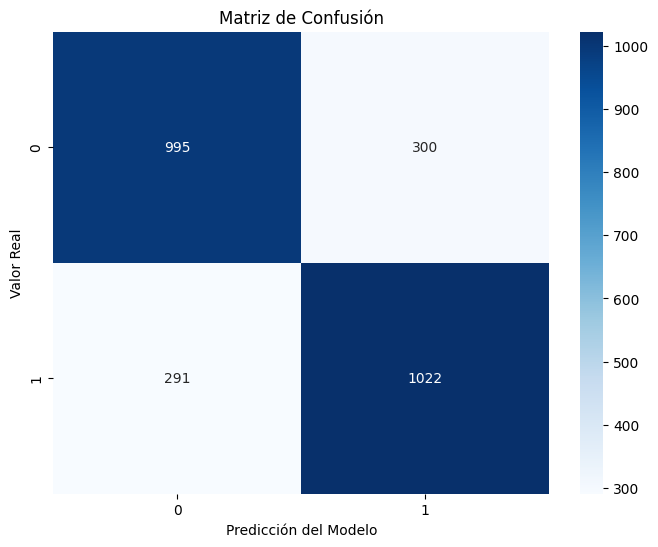

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score

y_predict = model.predict(X_test) > 0.5

print("Accuracy:", accuracy_score(y_test, y_predict))
print("F1:", f1_score(y_test, y_predict))

matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

In [27]:
pred_kaggle = model.predict(X_kaggle) > 0.5

submission = pd.DataFrame({
    "PassengerId": ids_kaggle,
    "Transported": pred_kaggle.ravel()
})
submission.to_csv("submission.csv", index = False)
print(submission["Transported"].value_counts())

from google.colab import files
files.download("submission.csv")

134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Transported
True     2222
False    2055
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>